##### 先安装：http://landinghub.visualstudio.com/visual-cpp-build-tools
- ```pip install pystan```
- ```pip install fbprophet```  or  ```conda install -c conda-forge fbprophet```
- ```conda install plotly -y ```

In [2]:
%matplotlib inline
import pandas as pd
from fbprophet import Prophet
import matplotlib.pyplot as plt
import os
import warnings

warnings.filterwarnings("ignore") 

### 1、导入数据，预处理

In [3]:
df = pd.read_csv('air.csv')
df['DATE'] = pd.to_datetime(df['DATE'])
df.head()

,DATE,AIR
0,1949-01-01,112
1,1949-02-01,118
2,1949-03-01,132
3,1949-04-01,129
4,1949-05-01,121


In [5]:
df.dtypes

DATE    datetime64[ns]
AIR              int64
dtype: object

In [6]:
df['DATE'] = pd.DatetimeIndex(df['DATE'])
df.dtypes

DATE    datetime64[ns]
AIR              int64
dtype: object

In [7]:
# 按照fbprophet的输入限制，传入的DataFrame.columns 必须为['ds', 'y']
df = df.rename(columns={'DATE': 'ds', 'AIR': 'y'})
df.head(2)

,ds,y
0,1949-01-01,112
1,1949-02-01,118


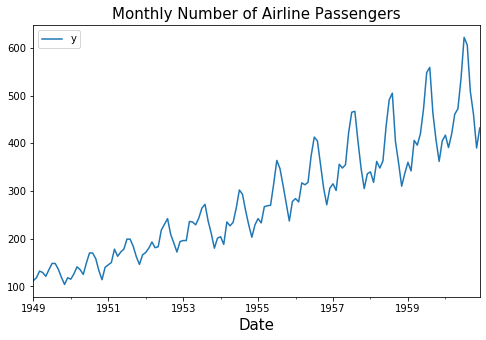

In [11]:
ax = df.set_index('ds').plot(figsize=(8, 5))
ax.set_title('Monthly Number of Airline Passengers', fontsize=15)
ax.set_xlabel('Date', fontsize=15)
plt.show()

### 使用加法模型

In [13]:
# 设置趋势的形式和预测值的置信区间为95% 
my_model = Prophet(
    growth='linear',
    yearly_seasonality='auto',
    weekly_seasonality=False, 
    seasonality_mode='additive',
    daily_seasonality=False,
    holidays=None,
    interval_width=0.95, 
)
my_model.fit(df)

预测

In [15]:
future_dates = my_model.make_future_dataframe(periods=36, freq='MS')
forecast = my_model.predict(future_dates)

forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail(5)

,ds,yhat,yhat_lower,yhat_upper
175,1963-08-01,649.511816,609.567073,695.629397
176,1963-09-01,601.983199,555.796403,645.762936
177,1963-10-01,565.980192,522.241910,611.338358
178,1963-11-01,534.021253,491.622685,577.886060
179,1963-12-01,563.611828,516.028671,606.015463


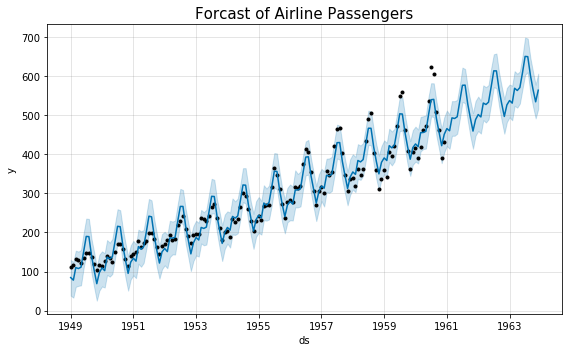

In [31]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.set_title('Forcast of Airline Passengers', fontsize=15)
my_model.plot(forecast, ax=ax, uncertainty=True)
plt.show()

图形上看，残差异方差比较明显！因此：
### 使用乘法模型

In [36]:
# 带节日效应的乘法模型建模
my_model = Prophet(
    growth='linear', 
    seasonality_mode='multiplicative',
    holidays=None,
    interval_width=0.95
)

# 增加节假日效应
my_model.add_country_holidays('China')

my_model.fit(df)

INFO:fbprophet:Disabling weekly seasonality. Run prophet with weekly_seasonality=True to override this.
INFO:fbprophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


节假日可以自定义，lower_window和upper_window代表节日向下(向上)影响的天数，此处仅做示例：

```
programmers_day = pd.DataFrame({
  'holiday': 'Chrismas',
  'ds': pd.to_datetime(['1957-10-24', '1958-10-24', '1959-10-24']),
  'lower_window': 3,
  'upper_window': 0,
})

shopping_day = pd.DataFrame({
  'holiday': 'New_year',
  'ds': pd.to_datetime(['1957-11-11', '1958-11-11', '1959-11-11']),
  'lower_window': 1,
  'upper_window': 0,
})

holidays = pd.concat((programmers_day, shopping_day))

my_model = Prophet(
    growth='linear', 
    seasonality_mode='multiplicative',
    holidays=holidays,
    interval_width=0.95
)
```

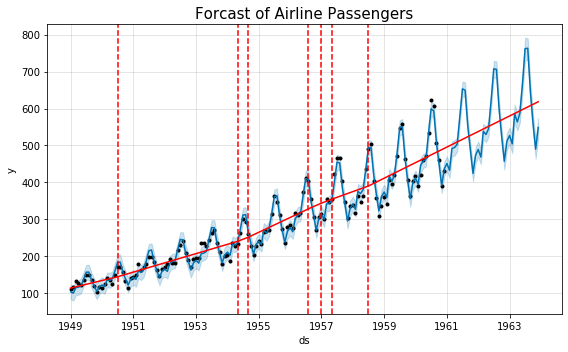

In [37]:
from fbprophet.plot import add_changepoints_to_plot

#  预测
future_dates = my_model.make_future_dataframe(periods=36, freq='MS')
forecast = my_model.predict(future_dates)

#  绘图
fig, ax = plt.subplots(figsize=(8, 5))
ax.set_title('Forcast of Airline Passengers', fontsize=15)
my_model.plot(forecast,uncertainty=True, ax=ax)   

#  绘制changepoints
add_changepoints_to_plot(ax, my_model, forecast)  
plt.show()

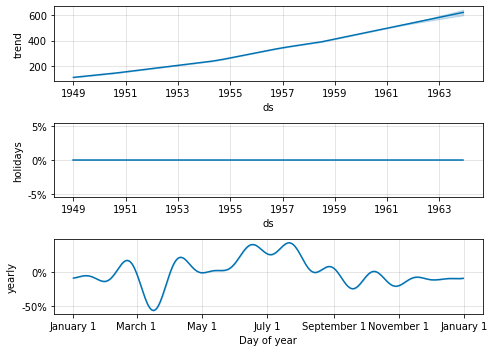

In [41]:
my_model.plot_components(forecast, figsize=(7, 5))
plt.show()

In [13]:
forecast.tail(5)

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,Chinese New Year,Chinese New Year_lower,Chinese New Year_upper,Dragon Boat Festival,...,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yearly,yearly_lower,yearly_upper,additive_terms,additive_terms_lower,additive_terms_upper,yhat
175,1963-08-01,604.339428,732.871444,793.585825,587.746760,621.142236,0.0,0.0,0.0,0.0,...,0.263121,0.263121,0.263121,0.263121,0.263121,0.263121,0.0,0.0,0.0,763.353921
176,1963-09-01,607.913734,618.437116,671.096144,590.587479,625.517689,0.0,0.0,0.0,0.0,...,0.061233,0.061233,0.061233,0.061233,0.061233,0.061233,0.0,0.0,0.0,645.138344
177,1963-10-01,611.372740,536.467051,589.461674,593.238919,629.750616,0.0,0.0,0.0,0.0,...,-0.082229,-0.082229,-0.082229,-0.082229,-0.082229,-0.082229,0.0,0.0,0.0,561.100031
178,1963-11-01,614.947046,467.138206,515.102815,596.039619,634.205369,0.0,0.0,0.0,0.0,...,-0.203082,-0.203082,-0.203082,-0.203082,-0.203082,-0.203082,0.0,0.0,0.0,490.062382
179,1963-12-01,618.406052,522.981558,577.376517,598.625850,638.706825,0.0,0.0,0.0,0.0,...,-0.112962,-0.112962,-0.112962,-0.112962,-0.112962,-0.112962,0.0,0.0,0.0,548.549776
